In [6]:
import kdsource.api as kds
import numpy as np

In [4]:
help(kds.write_mcpl)

Help on function write_mcpl in module kdsource.writemcpl:

write_mcpl(filename, *, ekin, x, y, z, ux, uy, uz, time, weight, pdgcode, polx=None, poly=None, polz=None, userflags=None, double_prec=False, force=False)
    Create MCPL file in the path indicated, based on particle data in numpy
    arrays. The arrays must of course all have equal length, with the exception
    that weight and pdgcode parameters are allowed to have a single scalar
    value, representing a fixed value of all particules. Additionally, polx,
    poly, polz, and userflags can be None to leave such field out of the
    file. The double_prec flag can be used to enable double precision storage of
    floating point values, and the force flag allows overwriting existing files.

    Note that the extension of the produced file will always end up as .mcpl.gz,
    so it is least surprising if the provided filename already has such an
    extension.



In [ ]:
file_path = "my_data.mcpl.gz"

empty_10 = np.zeros(10)
full_10 = np.ones(10)
kds.write_mcpl(filename=file_path, ekin=full_10, x=empty_10, y=empty_10, z=empty_10, ux=full_10, uy=empty_10, uz=empty_10, time=empty_10, weight=full_10, pdgcode=2112)

MCPL: Compressing file data.mcpl
MCPL: Compressed file into data.mcpl.gz


In [12]:
import mcpl
import pandas as pd

myfile=mcpl.MCPLFile(file_path,blocklength=2)
datas = []
for i,p in enumerate(myfile.particle_blocks):
    print("block no.", i)
    data = pd.DataFrame({
        'Kf': p.pdgcode,  # Particle PDG code
        'x': p.x,  # x-position
        'y': p.y,  # y-position
        'z': p.z,  # z-position
        'Vx': p.ux,  # Velocity in x-direction
        'Vy': p.uy,  # Velocity in y-direction
        'Vz': p.uz,  # Velocity in z-direction
        'e': p.ekin,  # Kinetic energy
        'Wt': p.weight  # Weight of the particle
    })
    datas.append(data)
data = pd.concat(datas, ignore_index=True)
data

block no. 0
block no. 1
block no. 2
block no. 3
block no. 4


,Kf,x,y,z,Vx,Vy,Vz,e,Wt
0,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
1,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
2,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
3,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
4,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
5,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
6,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
7,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
8,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
9,2112,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0


In [14]:
data.dtypes

Kf      int64
x     float32
y     float32
z     float32
Vx    float64
Vy    float64
Vz    float64
e     float64
Wt    float64
dtype: object

In [15]:
myfile=mcpl.MCPLFile("./examples/uniform/output.mcpl.gz",blocklength=100)
datas = []
for i,p in enumerate(myfile.particle_blocks):
    if i==1: break
    data = pd.DataFrame({
        'Kf': p.pdgcode,  # Particle PDG code
        'x': p.x,  # x-position
        'y': p.y,  # y-position
        'z': p.z,  # z-position
        'Vx': p.ux,  # Velocity in x-direction
        'Vy': p.uy,  # Velocity in y-direction
        'Vz': p.uz,  # Velocity in z-direction
        'e': p.ekin,  # Kinetic energy
        'Wt': p.weight  # Weight of the particle
    })
    datas.append(data)
data = pd.concat(datas, ignore_index=True)
data

,Kf,x,y,z,Vx,Vy,Vz,e,Wt
0,2112,-0.162481,-0.040676,0.06,-0.660523,0.190048,0.726355,2.500000e-08,1.0
1,2112,-0.029267,-0.583007,0.06,-0.547038,-0.737882,0.395322,2.500000e-08,1.0
2,2112,0.011129,0.043405,0.06,-0.497699,0.456605,0.737433,2.500000e-08,1.0
3,2112,0.215334,0.099948,0.06,0.123330,0.753316,0.645991,2.500000e-08,1.0
4,2112,0.276657,-0.141431,0.06,0.950695,0.016866,0.309668,2.500000e-08,1.0
...,...,...,...,...,...,...,...,...,...
95,2112,-0.164676,0.330439,0.06,0.379884,0.696097,0.609210,2.500000e-08,1.0
96,2112,-0.096169,0.080179,0.06,-0.122769,0.956632,0.264165,2.500000e-08,1.0
97,2112,-0.098242,-0.198568,0.06,-0.471250,0.169412,0.865577,2.500000e-08,1.0
98,2112,-0.335520,-0.083919,0.06,0.288980,-0.109987,0.950996,2.500000e-08,1.0


In [16]:
kds.write_mcpl(filename=file_path, ekin=data["e"], x=data["x"], y=data["y"], z=data["z"],
                ux=data["Vx"], uy=data["Vy"], uz=data["Vz"], time=np.zeros_like(data["Kf"]), weight=data["Wt"], pdgcode=data["Kf"])

MCPL: Compressing file data.mcpl
MCPL: Compressed file into data.mcpl.gz


In [1]:
import kdsource.api as kds  # Importing the KDSource Python API

In [2]:
kds.Geometry?

Init signature: kds.Geometry(metrics, trasl=None, rot=None)
Docstring:      <no docstring>
Init docstring:
Object defining particle variables treatment (metrics).

The main function of a Geometry is definig a transformation from
particle variables to certain parametrized variables, which can
be more suitable for applying KDE.

Parameters
----------
metrics: list
    List of metrics for each subset of variables. They must
    cover all particle variables (energy, position,
    direction and time).
trasl: array-like, optional
    Spatial traslation for source. Default is no traslation.
rot: numpy.ndarray or scipy.spatial.transform.Rotation, optional
    Spatial rotation for source. Can be a scipy Rotation object,
    or any array-like which can be used to generate a scipy
    Rotation object (rotation vector, quaternion or rotation
    matrix). Rotation is applied after traslation in transform,
    and before traslation in inverse_transform. Default is no
    rotation.
File:           ~/

In [3]:
kds.Metric?

Init signature: kds.Metric(partvars, varnames, units, volunits)
Docstring:      <no docstring>
Init docstring:
Abstract object defining metrics for a subset of variables.

The main function of a Metric is definig a transformation from a
subset of particle variables to certain parametrized variables,
which can be more suitable for applying KDE.

See geom._metrics for available metrics.

Parameters
----------
partvars: list of int
    Indices of the particle variables to parametrize (see
    varnames global list).
varnames: list of str
    Names of parametrized variables.
units: list of str
    Units of each parametrized variable.
volunits: str
    Units of the product of variables to parametrize.
File:           ~/miniconda3/envs/brightify_env_0/lib/python3.12/site-packages/kdsource/geom.py
Type:           type
Subclasses:     Geometry, Energy, Lethargy, Wavelength, Time, Decade, Vol, SurfXY, SurfR, SurfR2, ...

In [4]:
kds.geom._metrics

{'Energy': kdsource.geom.Energy,
 'Lethargy': kdsource.geom.Lethargy,
 'Wavelength': kdsource.geom.Wavelength,
 'Vol': kdsource.geom.Vol,
 'SurfXY': kdsource.geom.SurfXY,
 'SurfR': kdsource.geom.SurfR,
 'SurfR2': kdsource.geom.SurfR2,
 'SurfCircle': kdsource.geom.SurfCircle,
 'Guide': kdsource.geom.Guide,
 'Isotrop': kdsource.geom.Isotrop,
 'Polar': kdsource.geom.Polar,
 'PolarMu': kdsource.geom.PolarMu,
 'Time': kdsource.geom.Time,
 'Decade': kdsource.geom.Decade}

In [5]:
my_energy = kds.geom.Energy()
#my_lethargy = kds.geom.Lethargy()

In [6]:
type(my_energy)

kdsource.geom.Energy

In [7]:
for k,v in my_energy.__dict__.items():
    print(k, str(v))

partvars [0]
dim 1
varnames ['ekin']
varmap {'ekin': 0}
units ['MeV']
volunits MeV


In [8]:
# for k,v in my_lethargy.__dict__.items():
#     print(k, str(v))

In [9]:
my_position = kds.geom.Vol()
my_time = kds.geom.Time()
my_directions = kds.geom.Isotrop()

In [10]:
my_geometry = kds.Geometry([
    my_energy, my_time, my_position, my_directions
])

In [11]:
for k,v in my_geometry.__dict__.items():
    print(k, str(v))

partvars range(0, 8)
dim 8
varnames ['ekin', 't', 'x', 'y', 'z', 'dx', 'dy', 'dz']
varmap {'ekin': 0, 't': 1, 'x': 2, 'y': 3, 'z': 4, 'dx': 5, 'dy': 6, 'dz': 7}
units ['MeV', 'ms', 'cm', 'cm', 'cm', '[dir]', '[dir]', '[dir]']
volunits MeV ms cm^3 [dir]^3
ms [<kdsource.geom.Energy object at 0x70c4caa66e70>, <kdsource.geom.Time object at 0x70c4cac2b860>, <kdsource.geom.Vol object at 0x70c4caa84dd0>, <kdsource.geom.Isotrop object at 0x70c4cab6fd40>]
trasl None
rot None


In [12]:
kds.KDSource?

Init signature: kds.KDSource(plist, geom, bw='auto', J=1.0, kernel='gaussian')
Docstring:      <no docstring>
Init docstring:
Object representing Kernel Density Estimation (KDE) sources.

A KDSource object is based on a particle list in MCPL format,
wrapped in a PList object. It also includes a Geometry object,
which defines variables (energy, position, direction) treatment.
Having these basic components, KDSource can fit (optimize) a KDE
model on the particle list, creating a distributional source.

After optimization, analysis, plotting, etc., a KDSource can be
exported in XML format, for later use in Python or other
KDSource tools.

Parameters
----------
plist: PList object
    The PList wrapping the MCPL file containing the particle
    list.
geom: Geometry object
    The Geometry defining particle variables treatment.
bw: float, str or numpy.ndarray, optional
    Bandwidth or bandwidth selection method for KDE. If a float
    is passed, it is the bandwidth for all particles. If a


In [13]:
import kdsource

In [14]:
kdsource?

Type:        module
String form: <module 'kdsource' from '/home/jhonal/miniconda3/envs/brightify_env_0/lib/python3.12/site-packages/kdsource/__init__.py'>
File:        ~/miniconda3/envs/brightify_env_0/lib/python3.12/site-packages/kdsource/__init__.py
Docstring:  
Python module for creating and optimizing KDSource objects.

KDSource's are particle sources for Monte Carlo radiation transport
simulations. The full distribution and documentation can be found in the
project GitHub page:

    https://github.com/KDSource/KDSource

A KDSource object is based on a particle list in MCPL format (see
https://mctools.github.io/mcpl/), on which a Kernel Density Estimation
(KDE) is applied, using KDEpy library (see
https://github.com/tommyod/KDEpy).

With kdsource Python library you can create, optimize, and export
KDSource objects as XML files. These files can be later used as
distributional sources in other Monte Carlo simulations, using the tools
available in the full distribution.

If you use KD

In [21]:
kds.kde.bw_methods

{'auto': <function kdsource.kde.bw_auto(data, weights, grid=None, Nmlcv=-1, Nbatch=-1, Nknn=10, show=True, n_splits=10)>,
 'silv': <function kdsource.kde.bw_silv(dim, N_eff)>,
 'knn': <function kdsource.kde.bw_knn(data, weights=None, K_eff=100, k=None, batch_size=10000)>,
 'mlcv': <function kdsource.kde.bw_mlcv(data, weights=None, n_splits=10, seed=None, grid=None, show=True)>}

In [22]:
# Step 1: Load your original MCPL particle track list file
my_input_file_path = "./examples/uniform/output.mcpl.gz"

my_input_plist = kds.PList(filename=my_input_file_path,
                           readformat="mcpl",
                           pt="n",
                           trasl=None,
                           rot=None,
                           switch_x2z=False,
                           set_params=True)

# Step 2: Configure and fit the Adaptive Multivariate KDE model
my_source = kds.KDSource(
    plist=my_input_plist, geom=my_geometry, bw="silv", J=1.0, kernel="gaussian"
)


Using existing file ./examples/uniform/output.mcpl.gz
sum_weights = 21580959.0
p2 = 21580959.0
N = 21580959
N_eff = 21580959.0


In [16]:
[attr for attr in dir(my_source) if attr[0:2]!="__"]

['J',
 'R',
 'bw_method',
 'evaluate',
 'fit',
 'fitted',
 'geom',
 'kde',
 'kernel',
 'plist',
 'plot2D_integr',
 'plot2D_point',
 'plot_E',
 'plot_integr',
 'plot_point',
 'plot_t',
 'save',
 'scaling']

In [23]:
vars(my_source.plist)

{'filename': './examples/uniform/output.mcpl.gz',
 'pt': 'n',
 'trasl': None,
 'rot': None,
 'x2z': False,
 'params_set': True,
 'sum_weights': np.float64(21580959.0),
 'p2': np.float64(21580959.0),
 'N': 21580959,
 'N_eff': np.float64(21580959.0)}

In [25]:
my_source.fitted, my_source.bw_method

(False, 'silv')

In [26]:
my_source.fit(N=10000)

Using 10000 particles for fit.
Calculating bw ... 
Done
Optimal bw (silv) = [[4.30036184e-01 3.90789577e-04 1.23827303e-01 1.26316046e-01
  8.00658559e-10 2.38579327e-01 2.38579327e-01 2.38579327e-01]]


In [41]:
vars(my_source.geom)

{'partvars': range(0, 8),
 'dim': 8,
 'varnames': ['ekin', 't', 'x', 'y', 'z', 'dx', 'dy', 'dz'],
 'varmap': {'ekin': 0,
  't': 1,
  'x': 2,
  'y': 3,
  'z': 4,
  'dx': 5,
  'dy': 6,
  'dz': 7},
 'units': ['MeV', 'ms', 'cm', 'cm', 'cm', '[dir]', '[dir]', '[dir]'],
 'volunits': 'MeV ms cm^3 [dir]^3',
 'ms': [<kdsource.geom.Energy at 0x7d3a29d9fd70>,
 'trasl': None,
 'rot': None}

In [45]:
my_source.kde.fit?

Signature: my_source.kde.fit(data, weights=None)
Docstring:
Fit the KDE to the data. This validates the data and stores it.
Computations are performed upon evaluation on a grid.

Parameters
----------
data: array-like
    The data points.
weights: array-like
    One weight per data point. Numbers of observations must match
    the data points.

Returns
-------
self
    Returns the instance.

Examples
--------
>>> data = [1, 3, 4, 7]
>>> weights = [3, 4, 2, 1]
>>> kde = TreeKDE().fit(data, weights=None)
>>> kde = TreeKDE().fit(data, weights=weights)
>>> x, y = kde()
File:      ~/miniconda3/envs/brightify_env_0/lib/python3.12/site-packages/KDEpy/TreeKDE.py
Type:      method

In [27]:
my_source.fitted

True

[<Figure size 640x480 with 1 Axes>,
 [array([4.00232558e-16, 4.01170311e-01, 5.37277755e-01]),
  array([2.17539105e-10, 6.88724483e-03, 7.97040811e-03])]]

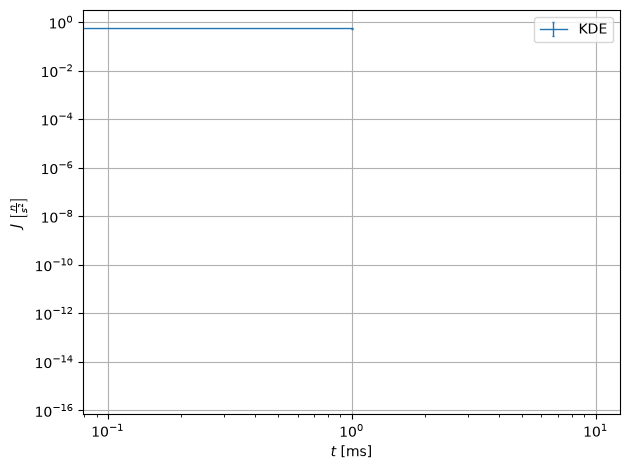

In [31]:
import numpy as np
my_source.plot_t(np.array([-1,0,1]))

In [41]:
my_source.kde.data

array([[ 2.50000003e-08,  6.70407397e-01, -5.64275606e-01, ...,
        -1.19058425e+00,  3.42558836e-01,  1.30924509e+00],
       [ 2.50000003e-08,  1.20174180e+00, -1.01641374e-01, ...,
        -9.86029887e-01, -1.33002217e+00,  7.12563121e-01],
       [ 2.50000003e-08,  4.35138113e-01,  3.86486287e-02, ...,
        -8.97095527e-01,  8.23024216e-01,  1.32921438e+00],
       ...,
       [ 2.50000003e-08,  1.27305014e+00,  9.84056009e-02, ...,
        -8.06618162e-01,  1.51619948e+00,  5.47235216e-01],
       [ 2.50000003e-08,  7.10821376e-01, -2.65878067e-01, ...,
        -1.09562543e+00,  1.16556383e+00,  8.30678022e-01],
       [ 2.50000003e-08,  7.35676016e-01,  1.67599095e+00, ...,
         8.64402083e-01,  1.18555943e+00,  1.04700429e+00]],
      shape=(10000, 8))

[<Figure size 640x480 with 1 Axes>,
 [array([0.92769468, 0.92769468, 0.92769468, 0.92769468]),
  array([0.00780095, 0.00780095, 0.00780095, 0.00780095])]]

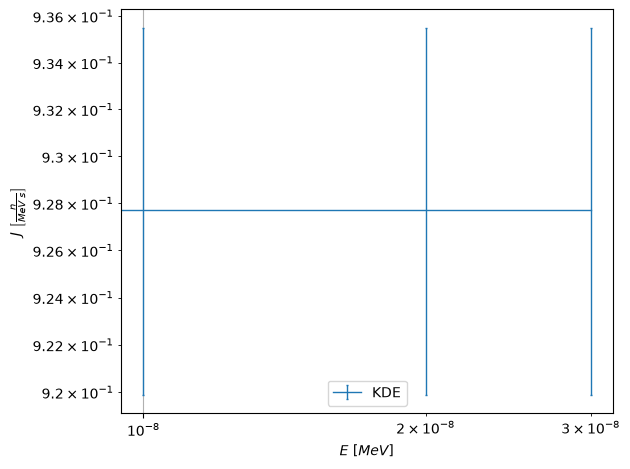

In [39]:
my_source.plot_E(grid_E=np.array([0,1e-8,2e-8,3e-8]))

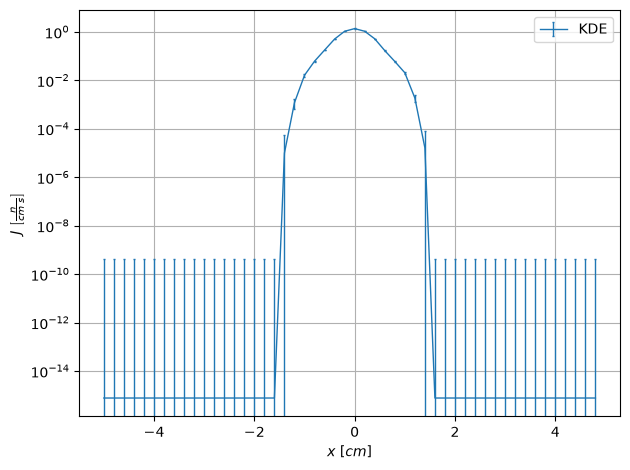

In [62]:
my_source.plot_integr(var="x", grid=np.arange(-5,5,0.2));

In [63]:
my_source.save()

Successfully saved parameters file _source.xml


'_source.xml'

In [64]:
kds.resample_to_mcpl("_source.xml", "generated_from_source.mcpl.gz", nout=100)

Reading xmlfile /home/jhonal/Brightify/_source.xml...
Done.
Resampling...
MCPL: Compressing file generated_from_source.mcpl
MCPL: Compressed file into generated_from_source.mcpl.gz
Successfully sampled 100 particles.


In [66]:
import mcpl
import pandas as pd

gen_file=mcpl.MCPLFile("generated_from_source.mcpl.gz")
datas = []
for i,p in enumerate(gen_file.particle_blocks):
    print("block no.", i)
    data = pd.DataFrame({
        'Kf': p.pdgcode,  # Particle PDG code
        'x': p.x,  # x-position
        'y': p.y,  # y-position
        'z': p.z,  # z-position
        'Vx': p.ux,  # Velocity in x-direction
        'Vy': p.uy,  # Velocity in y-direction
        'Vz': p.uz,  # Velocity in z-direction
        'e': p.ekin,  # Kinetic energy
        'Wt': p.weight  # Weight of the particle
    })
    datas.append(data)
data = pd.concat(datas, ignore_index=True)
data

block no. 0


,Kf,x,y,z,Vx,Vy,Vz,e,Wt
0,2112,-0.314750,0.087869,0.06,0.584076,0.630756,0.510883,0.452279,1.0
1,2112,-0.156093,0.229185,0.06,-0.096432,-0.959659,0.264113,0.659832,1.0
2,2112,-0.174374,0.424873,0.06,-0.459461,0.294224,0.838050,0.029960,1.0
3,2112,0.357392,-0.203787,0.06,-0.429220,0.178225,0.885441,0.347171,1.0
4,2112,0.375149,-0.023978,0.06,0.024622,0.518619,0.854651,0.051645,1.0
...,...,...,...,...,...,...,...,...,...
95,2112,-0.030924,-0.380031,0.06,-0.185489,0.388064,0.902774,0.001967,1.0
96,2112,-0.209845,-0.172571,0.06,-0.013932,-0.796015,0.605117,0.185403,1.0
97,2112,0.248228,0.310480,0.06,0.576967,-0.405146,0.709201,0.160421,1.0
98,2112,-0.219358,-0.501186,0.06,-0.605927,-0.767374,0.209737,0.046049,1.0
